In [1]:
#| include: false
# Global parameters and data (ported from wdi_hybrid_analysis.ipynb, cell 0).
import pandas as pd
start_year = 1995
discount_rate = 0.05
window_length = 15
annuity_factor = (1.0 - (1.0 + discount_rate) ** -window_length) / discount_rate

df = pd.read_csv('../data/wdi_africa_long.csv')
df = df[df['iso3'] != 'LSO'].reset_index(drop=True)  # Lesotho CPI has multiple uncorrected basket/base-year breaks (1999, 2002, 2009)
df['usd_per_lcu'] = 1 / df['exchange_rate']
df['Q'] = df['cpi'] / df['exchange_rate']   # real exchange rate, USD per local basket


# Exchange-rate regime classification, keyed by ISO3
# (copy of source/data_analysis_functions.py:31; importing that module would
# load the MFMOD extract, which this notebook does not use).
fx_regime = {
    # CFA Franc Zone - WAEMU
    'BEN': 'EUR-linked', 'BFA': 'EUR-linked', 'CIV': 'EUR-linked', 'GNB': 'EUR-linked',
    'MLI': 'EUR-linked', 'NER': 'EUR-linked', 'SEN': 'EUR-linked', 'TGO': 'EUR-linked',
    # CFA Franc Zone - CEMAC
    'CMR': 'EUR-linked', 'CAF': 'EUR-linked', 'TCD': 'EUR-linked', 'COG': 'EUR-linked',
    'GNQ': 'EUR-linked', 'GAB': 'EUR-linked',
    # Other EUR-pegged
    'COM': 'EUR-linked', 'CPV': 'EUR-linked',
    # Common Monetary Area (LSO itself is excluded from the data)
    'LSO': 'ZAR-linked', 'NAM': 'ZAR-linked', 'SWZ': 'ZAR-linked',
}

In [2]:
#| include: false
# Charting helpers (ported from wdi_hybrid_analysis.ipynb, cell 1:
# compute_V, shading helpers, and the two-axis country_chart).
import numpy as np
import altair as alt
# Render charts to static PNG in the kernel (needs vl-convert-python, installed
# in .venv). Viewer-proof: notebook front-ends (VS Code / JupyterLab) render raw
# vegalite JSON through their own vega bundle and can inject a dark display
# theme that overrides the spec config, hiding axis/legend/title text. PNGs
# also carry straight through to Quarto PDF. For interactive tooltips while
# exploring, temporarily switch to: alt.renderers.enable('html')
alt.renderers.enable('png', scale_factor=2.0)

# Theme pinning ALL ink colors, not just the background: dark-mode viewers
# (VS Code / JupyterLab) render vega-lite with the dark theme's light text,
# so forcing only a white background yields invisible axis labels, ticks and
# legends (white-on-white). alt.theme is the non-deprecated 5.5+ API.
@alt.theme.register('paper', enable=True)
def _paper_theme():
    ink = '#333333'
    return {'config': {
        'background': 'white',
        'title': {'color': ink},
        'axis': {'labelColor': ink, 'titleColor': ink, 'tickColor': ink,
                 'domainColor': ink, 'gridColor': '#dddddd'},
        'legend': {'labelColor': ink, 'titleColor': ink},
        'header': {'labelColor': ink, 'titleColor': ink},
        'text': {'color': ink},
    }}

def compute_V(cdata, t0, T, col='Q', rho=0.05):
    win = cdata[(cdata['year'] >= t0) & (cdata['year'] <= T)].sort_values('year')
    v = win[col].to_numpy()
    g = v / v[0] - 1.0
    t = np.arange(1, len(v) + 1, dtype=float)
    dfactors = (1.0 + rho) ** (-t)
    return float(np.sum(g * dfactors))

def _shade_and_text_layers(cdata, col, hline, shades):
    layers = []
    text_rows = []
    if shades and hline is not None:
        for shade in shades:
            y_start, y_end, color = shade[0], shade[1], shade[2]
            label = shade[3] if len(shade) > 3 else None
            seg = cdata[(cdata['year'] >= y_start) & (cdata['year'] <= y_end)].copy()
            seg['hline'] = hline
            layers.append(
                alt.Chart(seg).mark_area(opacity=0.3, color=color).encode(
                    x=alt.X('year:O'),
                    y=alt.Y(f'{col}:Q'),
                    y2=alt.Y2('hline:Q')
                )
            )
            if label is not None and not seg.empty:
                mid_year = int(seg['year'].iloc[len(seg)//2])
                mid_y = (seg[col].mean() + hline) / 2
                text_rows.append({'year': mid_year, 'y': mid_y, 'text': label, 'color': color})
    return layers, text_rows

def country_chart(iso3, start_year=start_year,
                  q_hline=None, shades=None,
                  usd_hline=None, usd_shades=None,
                  usd_y_range=None, h_y_range=None,
                  price_base_year=None):
    cdata = df[(df['iso3'] == iso3) & (df['year'] >= start_year)].dropna(subset=['usd_per_lcu', 'Q']).copy()
    country_name = cdata['country'].iloc[0]

    # Optional third series: the price level, normalised to 1 in the base year.
    # It shares the left-hand axis with Q because both are indices and
    # Q = P * (1/S) - the point being that Q's path is P's smooth climb times
    # the nominal rate's fall. Vega-Lite can only place two y-axes.
    p_label = None
    if price_base_year is not None:
        p_base = df[(df['iso3'] == iso3) & (df['year'] == price_base_year)]['cpi'].iloc[0]
        cdata['P_idx'] = cdata['cpi'] / p_base
        p_label = f'P ({price_base_year}=1)'

    legend_setting = alt.Legend(title="Series", orient="bottom")
    # Pinned series colours, in legend order: Q, P, 1/S. The legend follows the
    # scale domain, and pinning also stops a third domain value from re-sorting
    # the domain and recolouring Q and 1/S in the panels that show P.
    series_scale = alt.Scale(
        domain=['Q'] + ([p_label] if p_label else []) + ['1/S'],
        range=['#4c78a8'] + (['#54a24b'] if p_label else []) + ['#f58518'],
    )

    usd_scale = alt.Scale(domain=list(usd_y_range)) if usd_y_range is not None else alt.Undefined
    q_scale = alt.Scale(domain=list(h_y_range)) if h_y_range is not None else alt.Undefined

    # --- RIGHT AXIS: 1/S ---
    # Drawn first so the Q/P group layers on top of the 1/S shading; the axis
    # side is set by the explicit orient, not by layer order.
    usd_layers = []
    usd_shade_layers, usd_text_rows = _shade_and_text_layers(cdata, 'usd_per_lcu', usd_hline, usd_shades)
    usd_layers.extend(usd_shade_layers)

    usd_layers.append(
        alt.Chart(cdata).mark_line(point=True).encode(
            x=alt.X('year:O', title='Year'),
            y=alt.Y('usd_per_lcu:Q', title='1/S  (USD per LCU)',
                    axis=alt.Axis(orient='right'), scale=usd_scale),
            color=alt.Color('Metric:N', scale=series_scale, legend=legend_setting),
            tooltip=['year', 'usd_per_lcu']
        ).transform_calculate(Metric="'1/S'")
    )

    if usd_hline is not None:
        usd_layers.append(
            alt.Chart(pd.DataFrame({'y':[usd_hline]})).mark_rule(color='blue', strokeDash=[4,4]).encode(
                y=alt.Y('y:Q')
            )
        )

    if usd_text_rows:
        usd_layers.append(
            alt.Chart(pd.DataFrame(usd_text_rows)).mark_text(fontSize=14, fontWeight='bold').encode(
                x=alt.X('year:O'),
                y=alt.Y('y:Q'),
                text=alt.Text('text:N'),
                color=alt.Color('color:N', scale=None, legend=None)
            )
        )

    usd_chart = alt.layer(*usd_layers)

    # --- LEFT AXIS: Q, and P when requested ---
    q_axis_title = ('Q = CPI / S  (USD per local basket)' if p_label is None
                    else f'Q = P / S  (USD per local basket), and P ({price_base_year}=1)')
    q_layers = []
    q_shade_layers, q_text_rows = _shade_and_text_layers(cdata, 'Q', q_hline, shades)
    q_layers.extend(q_shade_layers)

    q_layers.append(
        alt.Chart(cdata).mark_line(point=True).encode(
            x=alt.X('year:O', title='Year'),
            y=alt.Y('Q:Q', title=q_axis_title, axis=alt.Axis(orient='left'), scale=q_scale),
            color=alt.Color('Metric:N', scale=series_scale, legend=legend_setting),
            tooltip=['year', 'Q']
        ).transform_calculate(Metric="'Q'")
    )

    if q_hline is not None:
        q_layers.append(
            alt.Chart(pd.DataFrame({'y':[q_hline]})).mark_rule(color='red', strokeDash=[4,4]).encode(
                y=alt.Y('y:Q')
            )
        )

    if q_text_rows:
        q_layers.append(
            alt.Chart(pd.DataFrame(q_text_rows)).mark_text(fontSize=14, fontWeight='bold').encode(
                x=alt.X('year:O'),
                y=alt.Y('y:Q'),
                text=alt.Text('text:N'),
                color=alt.Color('color:N', scale=None, legend=None)
            )
        )

    if p_label is not None:
        q_layers.append(
            alt.Chart(cdata).mark_line(point=True).encode(
                x=alt.X('year:O', title='Year'),
                # Same axis spec as the Q layer: the two specs merge into the
                # single left-hand axis, whose domain unions both series.
                # (axis=None here instead suppresses that merged axis.)
                y=alt.Y('P_idx:Q', title=q_axis_title,
                        axis=alt.Axis(orient='left'), scale=q_scale),
                color=alt.Color('Metric:N', scale=series_scale, legend=legend_setting),
                tooltip=['year', 'P_idx']
            ).transform_calculate(Metric=f"'{p_label}'")
        )

    q_chart = alt.layer(*q_layers)

    return alt.layer(usd_chart, q_chart).resolve_scale(y='independent').properties(
        title=f"{country_name} (from {start_year})",
        width=500,
        height=350
    )

dza_data = df[(df['iso3']=='DZA') & (df['year']>=start_year)].dropna(subset=['Q'])
q_1998 = dza_data.loc[dza_data['year']==1998, 'Q'].iloc[0]
usd_1998 = df[(df['iso3']=='DZA') & (df['year']==1998)]['usd_per_lcu'].iloc[0]
usd_2013 = df[(df['iso3']=='DZA') & (df['year']==2013)]['usd_per_lcu'].iloc[0]
usd_2000 = df[(df['iso3']=='DZA') & (df['year']==2000)]['usd_per_lcu'].iloc[0]
V_red   = compute_V(dza_data, 1998, 2006, col='Q')/annuity_factor
V_green = compute_V(dza_data, 2006, 2013, col='Q')/annuity_factor
V_total = (V_red+V_green)
V_blue  = compute_V(dza_data, 1998, 2013, col='usd_per_lcu')/annuity_factor
print(f"Q_1998 (Algeria)         = {q_1998:.4f}")
print(f"usd_per_lcu_1998 (Algeria) = {usd_1998:.6f}")
print(f"usd_per_lcu_2013 (Algeria) = {usd_2013:.6f}")
print(f"usd_per_lcu_2000 (Algeria) = {usd_2000:.6f}")
print(f"usd_per_lcu_1998to2013 (Algeria) = {(usd_1998-usd_2013)/usd_1998:.6f}")
print(f"usd_per_lcu_1998to2000 (Algeria) = {(usd_1998-usd_2000)/usd_1998:.6f}")
print(f"V_Q(1998,2006)            = {V_red:.4f}")
print(f"V_Q(2006,2013)            = {V_green:.4f}")
print(f"V_Q(1998,2013)            = {V_total:.4f}")
print(f"V_1/S(1998,2013)          = {V_blue:.4f}")



Q_1998 (Algeria)         = 1.1643
usd_per_lcu_1998 (Algeria) = 0.017024
usd_per_lcu_2013 (Algeria) = 0.012599
usd_per_lcu_2000 (Algeria) = 0.013287
usd_per_lcu_1998to2013 (Algeria) = 0.259920
usd_per_lcu_1998to2000 (Algeria) = 0.219517
V_Q(1998,2006)            = -0.0699
V_Q(2006,2013)            = 0.1054
V_Q(1998,2013)            = 0.0355
V_1/S(1998,2013)          = -0.1895


# Motivation: the currency mismatch that blocks the deal

Currency mismatch between local currency revenues in developing countries and the cost of hard currency debt service holds up many infrastructure finance transactions. When such hard currency credit has been provided for developing country electricity generation infrastructure, the currency risk has often been placed on the national utility - "offtaker" - through dollarised power purchase agreements (PPAs). This has led to an exacerbation of these utilities' financial woes from currency devaluations. This has had the knock-on effect of increasing offtaker risk for such projects and generating an additional impediment to the financing of electricity generation projects. Capital costs for such projects are thus affected two-fold by the currency mismatch, by the direct currency risk and by the induced offtaker risk.

This analysis suggests that, when inflation is born by the consumer, the residual - real - currency risk, is limited when borne by an institution with sufficiently long term capital. This is due to the relatively long period in the cyclicality of the real exchange rate. An institution exposed to real exchange rate risk and able to weather adverse movements lasting 5-10 years will bear significantly less risk than is commonly assumed, even for developing country currency risk. As a result, such institutions are well placed to offer affordable cover to such transaction.

This proposal, analogous to the emergency liquidity facility of the EcoInvest Brazil platform provided by the IaDB, provides insurance against shrotfalls in hard currency debt service *triggered by adverse movements the exchange and inflation rates*. The pre-requisite for cover is that revenues are indexed to local currency inflation through appropriate clauses in the power purchase agreement. As we show below, this strips inflation out of the nominal exchange rate risk, leaving only a real exchange rate risk component, which is bounded and cyclical, and consequently allows for affordable cover, as we show below.

## Notation

For country $i$, and projects with financial close at $\underline{t}=0$, maturity $\bar{t}$, and tenor $n=\bar{t}-\underline{t}$:

- $P_{i,t}$ — domestic price level (CPI), in LCU; $p\equiv\ln P$, inflation $\pi=\dot p$
- $S_{i,t}$ — nominal exchange rate in LCU per USD, so $\dot s>0$ is a depreciation of the local currency in dollar terms; $s\equiv\ln S$
- $Q_{i,t}\equiv P_{i,t}/S_{i,t}$ — the domestic price level divided by the nominal exchange rate, which is also equal to the real exchange rate times the USD price level. Its growth captures the growth of the USD value of a fixed basket of domestic goods. A rise is a real *appreciation*, the domestic basket brings you more dollars: $q\equiv\ln Q=p-s$ and $\dot q=\pi-\dot s$.
- $\tau,\ c,\ E$ — real tariff, real unit cost, constant energy output
- $\rho$ — discount rate
- $A_{n,\rho}\equiv\dfrac{1-(1+\rho)^{-n}}{\rho}$ — annuity factor, or present value of a unit annuity over n periods at discount rate $\rho$
- $R_{i,t}\equiv Q_{i,t}/Q_{i,0}-1$ — cumulative (holding-period) return on $Q$ since $t=0$
- $D$ — debt stock; $\text{LLCR}$ — loan-life coverage ratio
- $\Pi_{i,n,\rho}$ — discounted loan life P&L; $L_i$ — Facility loss; $G$ — the Facility
- $V_{i,n,\rho}$ — macro value to debt ratio
- $\Psi$ — level annual premium; $\Delta r$ — margin-equivalent interest-rate add-on
- $\mathbb{E}[\cdot]$ — expectation

In the code below, the DataFrame column `Q` holds $Q_{i,t}$ (computed as `cpi / exchange_rate`), and `exchange_rate` holds $S_{i,t}$.


## A stylised project

The analysis below focuses on $Q_{i,t}=P_{i,t}/S_{i,t}$, where $P_i$ is the domestic price level and $S_i$ the nominal exchange rate in LCU per USD. As an index, $Q$ measures the change in the USD value of a fixed local basket of goods. If the local price of electricity is made to grow at the national inflation rate, $Q$ also measures the evolution of the USD value of a MWh. It is easy to see (and we show in detail below) that when tariffs are inflation-adjusted, $Q$ is a good measure of the dollar cash flows available for debt service.

Consider, for simplicity, a project generating a constant amount of energy $E$ from $t=0$ to $T$ at constant real unit cost $c$, excluding hard-currency debt service, and selling at an inflation-indexed real tariff $\tau$. Nominal local-currency revenue is $P_{i,t}\,\tau\,E$ and earnings before debt service are $P_{i,t}(\tau-c)E$. That is, local-currency cash flows available for debt service (CFADS) are a constant growing at the rate of inflation, and CFADS in dollars are

$$
\text{CF}^{\$}_{i,t} \;=\; Q_{i,t}\,(\tau-c)\,E .
$$

For the sake of exposition, we consider a stylised project in which all debt is in hard currency and debt service is constant ($DS_t = \mathbb{C}$) dollars over the entire repayment period.

The annuity factor, for which the formula below pops out of the finite geometric sum, is defined as the present value of a 1 unit annuity for $n$ years at a discount rate of $\rho$:
$$
A_{n,\rho}=\frac{1-(1+\rho)^{-n}}{\rho}
$$

By that definition, the principal that is borrowed at an interest rate $\rho$ and repaid with a constant annuity $\mathbb{C}$ over $n$ years is simply
$$
D = A_{n,\rho} \cdot \mathbb{C}
$$

We will assume that the debt has been sized so that annual debt service is exactly equal to the dollar CFADS in the first year of operations (and of debt service):

$$\text{CF}^{\$}_{i,0} = Q_{i,0}(\tau-c)E \equiv DS_t = \mathbb{C} = D/A_{n,\rho}$$

This automatically results in a year zero debt service coverage ratio (DSCR) of one, leaving zero buffer for future FX swings; dollar debt service is constant by assumption and CFADS only just cover the debt service requirement when $Q_{i,t} = Q_{i,0}$ is constant. The assumption also implies zero profit in the constant $Q$ scenario, a debt service shortfall (and technical default) when $Q$ decreases and a surplus when $Q$ increases.

Project finance structures usually require a debt service coverage ratio (DSCR) greater than 120% as a buffer against various risks to which the cash flows are exposed. Still, our assumption of zero buffer is without loss of generality, since the main affordability result below is only strengthened if projected $\text{DSCR}_t>1$.


Mathematically the PnL (surplus or shortfall) in year $t$ due to currency or price movements is
$$
\text{PL}_t = \text{CF}^{\$}_{i,t} - DS_t = DS_t \frac{\text{CF}^{\$}_{i,t} - \text{CF}^{\$}_{i,0}}{\text{CF}^{\$}_{i,0}} = DS_t \cdot  R_{i,t}
$$
where 
$$
R_{i,t} \;\equiv\; \frac{\text{CF}^{\$}_{i,t}}{\text{CF}^{\$}_{i,0}} - 1 \;=\; \frac{Q_{i,t}}{Q_{i,0}} - 1
$$

is the cumulative return on $Q$ since close — a holding-period return, not a per-period flow.

Given a discount rate $\rho$, the present value at financial close of the loan life P&L is

$$
\Pi_i \;=\; \int_{0}^{T}DS_t \frac{R_{i,t}}{(1+\rho)^{t}}\,dt = D \cdot \underbrace{\frac{1}{A_{\bar{t}-\underline{t},\rho}}\int_{0}^{T} \frac{R_{i,t}}{(1+\rho)^{t}}\,dt}_{V_{i,\underline{t},\bar{t},\rho}}
$$
Through the constant debt service assumtion we can calculate the profit as $V_i$ times the total debt stock. Time varying repayment profiles reweight the integral but don't have a material impact on the results as we show in the robustness checks below. 

As such the main object of interest is the *macro value to debt ratio*, calculated through the integral
$$
\frac{\Pi_i}{D} = V_{i,\underline{t},\bar{t},\rho} = \frac{1}{A_{\bar{t}-\underline{t},\rho}} \int_0^T \frac{1}{(1+\rho)^{t}} \frac{Q_{i,t}- Q_{i,0}}{Q_{i,0}} \,dt
$$


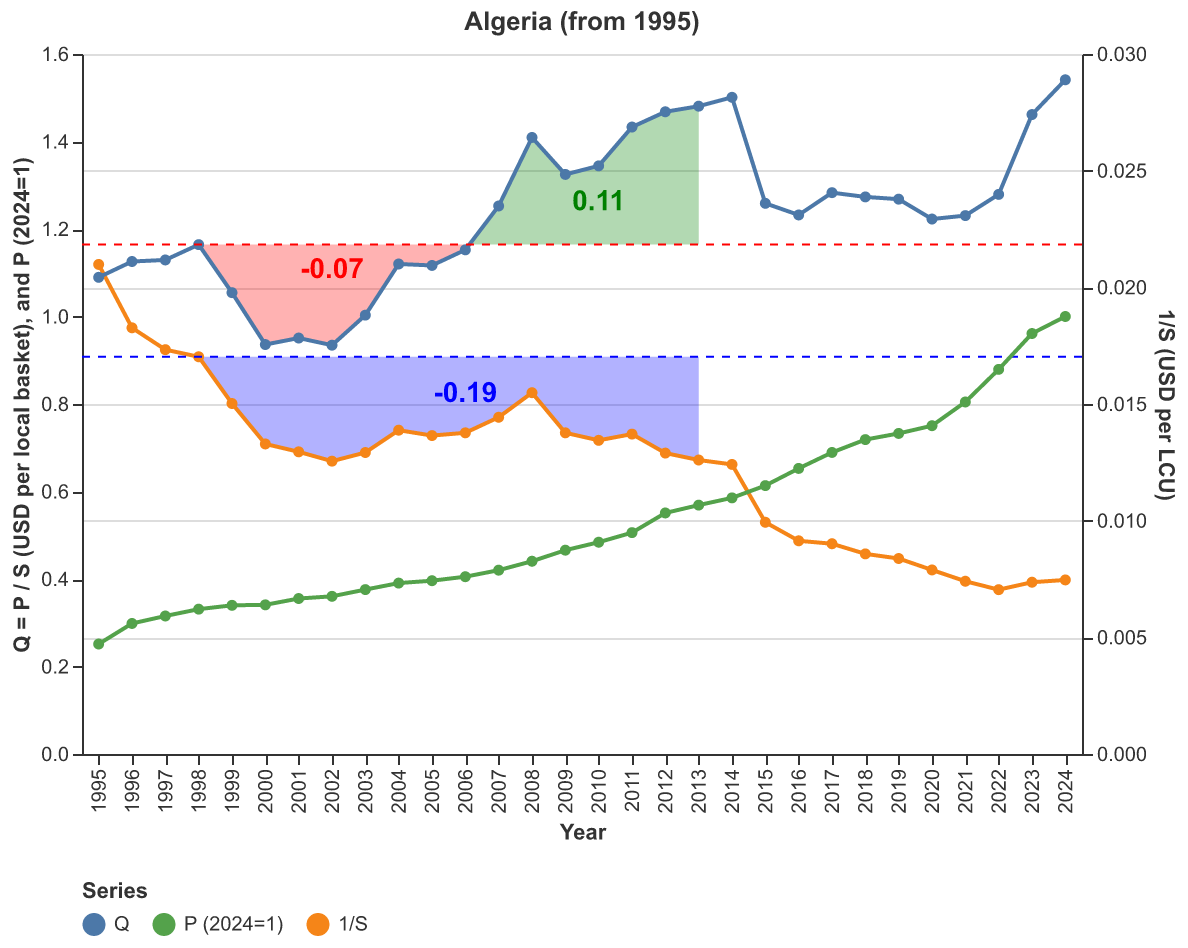

In [3]:
#| label: fig-dza
#| fig-cap: "Algeria 1995-2024: the real exchange rate Q = P/S (blue, left), the price level P (green, left) and the nominal rate 1/S (orange, right). Shading measures V over 1998-2006 (red), 2006-2013 (green) and, on the nominal rate, 1998-2013 (blue)."
DZA_chart = country_chart(
    'DZA',
    q_hline=q_1998,
    shades=[
        (1998, 2006, 'red',   f"{V_red:.2f}"),
        (2006, 2013, 'green', f"{V_green:.2f}"),
    ],
    usd_hline=usd_1998,
    usd_shades=[
        (1998, 2013, 'blue', f"{V_blue:.2f}"),
    ],
    usd_y_range=(0.006, 0.030),
    price_base_year=2024,
)
S_1998 = df[(df['iso3']=='DZA') & (df['year']==1998)]['usd_per_lcu'].iloc[0]
S_1999 = df[(df['iso3']=='DZA') & (df['year']==1999)]['usd_per_lcu'].iloc[0]
S_2000 = df[(df['iso3']=='DZA') & (df['year']==2000)]['usd_per_lcu'].iloc[0]
S_2002 = df[(df['iso3']=='DZA') & (df['year']==2002)]['usd_per_lcu'].iloc[0]
# print(f"{(S_2002-S_1998)/S_2002}")
# print(f"{100/S_1998}")
# print(f"{5873.8958*S_1999}")
# print(f"{5873.8958*S_2000}")
# dza_data
DZA_chart

## Inflation and the exchange rate

Consider the case of the Algerian Dinar to understand how the exchange rate and price level affect the macroeconomic exposure of a project with local currency revenues. The figure plots $Q_{i,t} = P_{i,t}/S_{i,t}$ for the 30 year period between 1995 and 2024, along with its components: the price level $P_{i,t}$ and the nominal exchange rate $1/S_{i,t}$ (in USD per LCU). In the plotted representation the growth rates of the components sum up visually to the growth rate of $Q$.

Consider the macroeconomic movements that a local currency project reaching financial close in 1998 and paying 15 years of hard currency debt service must contend with.

During that period the nominal exchange rate dropped 26% from 1.7 to 1.3 Dollar cents per Dinar, with the bulk of the depreciation (22%) taking place in the first two years. 

If the project had (admittedly unlikely) constant nominal Dinar cashflows, it would have had lower dollar CFADS than at financial close in every single year of its debt service (the orange path for $1/S_{i,t}$). Unhedged a constant Dinar cashflow would have been worth only 88% of its 1998 dollar value in 1999 and only 78% in 2000. If such a project had constant USD debt service commitments valued at 100% of the 1998 dollar value for the 15 years from 1998 to 2013, the depreciation would result in an inability to fully service the debt, amounting to a total shortfall of 19% of the original principal (in present value terms at financial close), or two years worth of debt service.

Looking instead at $Q_{i,t}$, we see that a project with inflation adjusted cashflows in Dinar would have also been in the red between 1998 and 2006, resulting in a debt service shortfall valued at 7% of the total debt in present value terms. However, between 2002 and 2013 $Q_{i,t}$ appreciated on account of inflation outpacing depreciation, generating a net gain relative to the 1998 level of 11% of the principal between 2006 and 2013, more than compensating for the shortfall between 1998 and 2006. 



## Solvency and liquidity

As the example of Algeria illustrates, for a project with inflation indexed local currency revenue and and hard currency debt service, the risk implied by the currency mismatch has two components: it is a long position on local inflation and a short position on appreciation of the dollar. In the example inflation comes in to compensate of an appreciation of the dollar. Macroeconomic theory predicts such compensatory movements over time and, as we shall see below, this is what happens more often than not in the historical macroeconomic series in Africa.

The eventual rebalancing of the real exchange rate through the inflation-exchange-rate dynamics ensures the long run solvency of a Dinar project in the 1998-2013 sample. However, such a project would still run into liquidity issues quite soon, as illustrated by the red area in the chart. Unless lender and borrower had accounted for a DSCR in excess of 150% along with a significant reserve account, standard debt covenants would put such a project into technical default by the 4th or 5th year. 

An emergency liquidity line to the borrower in hard currency could avert such a technical default and the consequent refinancing. Provided sufficient certainty in the eventual rebalancing of the real exchange rate ensuring solvency of the debtor, such an emergency liquidity line can be provided quite cheaply by an entity with sufficient solvency capital. The proposal below does just that.

## The emergency liquidity facility

Let the **Facility** $G$ offer an insurance product that, in return for an annual premium, provides emergency liquidity in case of currency depreciation to projects with hard currency debt.

Recall that $R_{i,t} = \frac{Q_{i,t}}{Q_{i,0}} - 1$ and consider again a project with inflation adjusted local currency revenues, constant hard currency debt service and $DSCR_t = 1$ for the entire repayment period.

Whenever a devaluation causes $R_{i,t}<0$, the facility $G$ advances $DS_t \cdot|R_{i,t}|$ so the project can meet its debt service payment; conversely, whenever $R_{i,t}>0$, the project escrows the surplus in an interest-bearing USD account to repay the facility at maturity $T$.

Recalling the Algerian currency and price movements, such facility would have provided the project with dollars worth 7% of the original loan between 1998 and 2006 and escrowed dollars worth 19% of the original loan between 2006 and 2013 (the red and green areas in the chart).

At the end of the repayment period, the facility returns any positive balance in the escrow account to the project. If the balance is negative, i.e. if the payouts exceeded the the value accumulated in the escrow account, the facility incurrs that loss.

Look at the path of $Q$ in Nigeria to understand the loss profile of such a facility.

In the graph below we trace all 15-year windows in the Nigerian data with a horizontal line starting at the value of $Q$ at the window starting point.

Whenever $Q$ is below a window's line, as it it between 1985 and 1993 for the window starting at 1985, a project servicing debt during that window will be short on dollars and require funds from the facility. Whenever $Q$ is above a window's line, as it is between 1993 and 1999 for the same window starting at 1985, the project has a dollar surplus and is paying into the escrow account. The cumulative discounted area between the line and $Q$ is the discounted loan life P&L over the 15-year window. Normalised by the annuity factor, it is the macro value to debt ratio. If it is negative, the facility incurrs a loss and we have drawn the horizontal line in red. If it is positive, no loss is incurred, the project gets reimbursed that amount out of the escrow account, and the horizontal line is painted in green.

The lines are drawn in incresingly darker shades, and a dot in the same shade painted on $Q$ at the end of the 15-year window.

Underneath the time series, underneath the dot representing the end of the 15-year window, we plot $V_{i,\underline{t},\bar{t},\rho}$, the macro value to debt ratio, measured in present value terms at the beginning of the window.

Between 1985 and 2024 there are 26 15-year windows. Of those, 22 had a positive terminal value, ranging from 17% to 136% of the debt stock. Four windows, those immediately preceding the 1999 abandonment of the dollar peg and subsequend devaluation, had negative terminal values, the largest reaching 55% of the project debt stock.



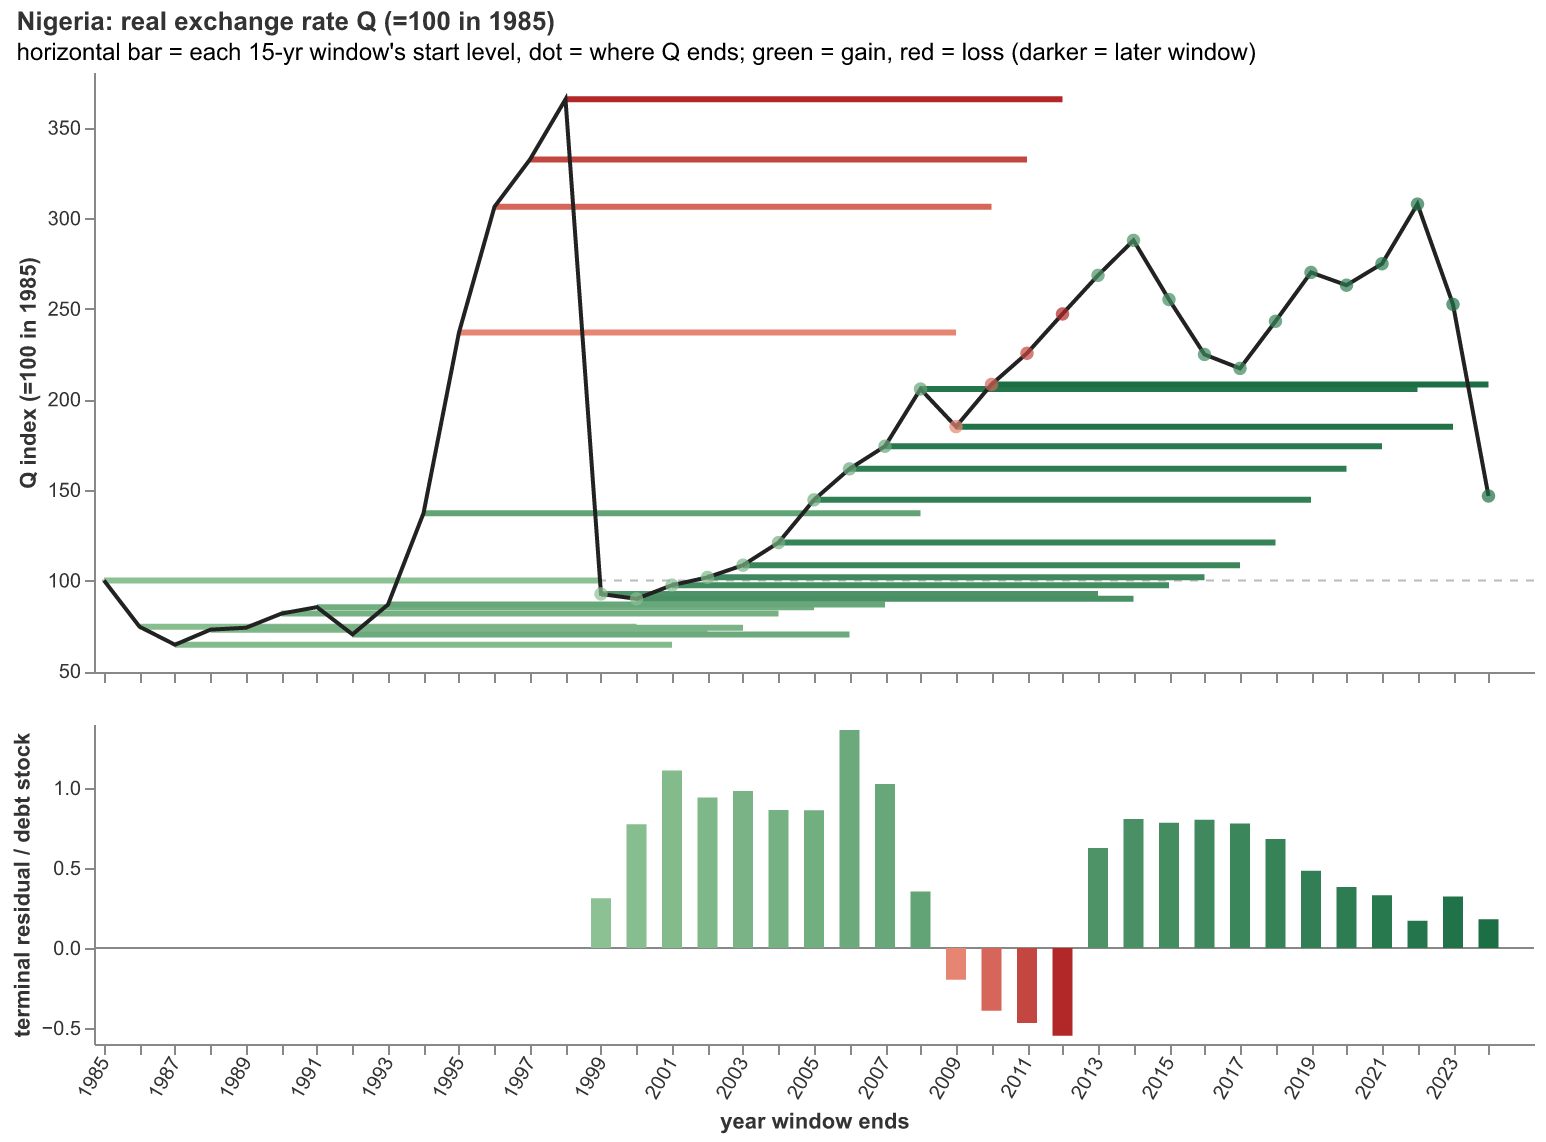

In [4]:
#| label: fig-windows-nga
#| fig-cap: "Nigeria: Q (indexed to first year) with every rolling 15-year window's start level and its terminal residual, green = gain, red = loss, shaded by window start."
# Ported from wdi_hybrid_analysis.ipynb, cell 6 (styled windows chart).
# --- Redesigned colored-windows chart (new version, for comparison with the cell above) ---
# Color = green (gain) / red (loss) with a light->dark shade by window start within each hue,
# used identically on each window's horizontal start-level marker, its end dot on the Q line,
# and its residual bar below. No gridlines; a yearly x-axis (rotated -60) labelled on the
# bottom panel only; the dashed-100 (top) and zero (bottom) reference lines are the anchors.
start_year = 1980
def compute_terminal_residuals_wdi(
    df,
    years=15,
    discount_rate=0.05,
    window_mode="rolling", # or "two_non_overlapping",  # 
    col="Q",
    start_year=None,
):
    """Mirror of source.data_analysis_functions.compute_terminal_residuals,
    operating directly on the wdi_africa_long-shaped df with columns:
    iso3, country, year, exchange_rate, cpi, usd_per_lcu, Q.

    For each country, slides a fixed-horizon window over the series in `col`,
    computes R_it = v/v[t0] - 1, discounts year-end cashflows back to start,
    and returns the present value of lifetime P&L, V_i, normalised by the
    annuity factor A to a PV per unit of debt stock.
    If `start_year` is given, df is filtered to year >= start_year before
    any windowing.
    """
    if start_year is not None:
        df = df[df["year"] >= start_year]

    af = (1 - (1 + discount_rate) ** -years) / discount_rate
    out = []

    for iso3, g in df.dropna(subset=[col]).groupby("iso3"):
        g = g.sort_values("year").reset_index(drop=True)
        n = len(g)
        if n < years:
            continue

        if window_mode == "two_non_overlapping":
            starts = list(range(0, n - years + 1, years))[:2]
        elif window_mode == "rolling":
            starts = list(range(0, n - years + 1))
        else:
            raise ValueError("window_mode must be 'two_non_overlapping' or 'rolling'")

        for i0 in starts:
            win = g.iloc[i0:i0 + years]
            if win[col].isna().any():
                continue

            base = float(win[col].iloc[0])
            R_it = (win[col].to_numpy() / base) - 1.0
            t = np.arange(1, years + 1, dtype=float)
            dfactors = (1.0 + discount_rate) ** (-t)

            V_i = float(np.sum(R_it * dfactors))
            net_pv_per_debt_stock = V_i / af
            loss = min(net_pv_per_debt_stock, 0.0)

            out.append({
                "iso3": iso3,
                "country": win["country"].iloc[0],
                "window_start": int(win["year"].iloc[0]),
                "window_end": int(win["year"].iloc[-1]),
                "baseline": base,
                "net_pv_by_debt_stock": net_pv_per_debt_stock,
                "loss": loss,
            })

    return pd.DataFrame(out)


def _ramp(t, light, dark):
    """Hex color interpolated between `light` (t=0) and `dark` (t=1) in RGB."""
    lo = tuple(int(light[i:i + 2], 16) for i in (1, 3, 5))
    hi = tuple(int(dark[i:i + 2], 16) for i in (1, 3, 5))
    return '#%02x%02x%02x' % tuple(round(a + (b - a) * t) for a, b in zip(lo, hi))


def country_windows_styled(iso3, years=window_length, discount_rate=discount_rate,
                           step=1, first_start=start_year, ypad_frac=0.05):
    res = compute_terminal_residuals_wdi(
        df[df['iso3'] == iso3], years=years, discount_rate=discount_rate,
        window_mode="rolling", col="Q", start_year=first_start).reset_index(drop=True)
    if step > 1:  # thin the rolling windows out if requested
        res = res[(res['window_start'] - res['window_start'].min()) % step == 0].reset_index(drop=True)

    g = (df[(df['iso3'] == iso3) & (df['year'] >= first_start)]
         .dropna(subset=['Q']).sort_values('year'))
    country_name = g['country'].iloc[0]
    q0 = float(g['Q'].iloc[0])
    base_year, last_year = int(g['year'].iloc[0]), int(g['year'].max())

    g = g.assign(idx=g['Q'] / q0 * 100.0)            # index = 100 in the first year
    idx_by_year = dict(zip(g['year'], g['idx']))

    # bivariate color: hue = sign of residual (green gain / red loss); within each hue,
    # lightness ranks the window by start date (light = earliest of that colour -> dark =
    # latest). Normalising per colour (not over all windows) keeps the gradient visible even
    # when one colour has only a few, tightly-clustered windows (e.g. a handful of late losses).
    s = res['window_start']
    sign_pos = res['net_pv_by_debt_stock'] >= 0

    def _shade(mask):
        sub = s[mask]
        if len(sub) == 0:
            return {}
        lo, sp = sub.min(), max(int(sub.max() - sub.min()), 1)
        return {int(ws): 0.25 + 0.6 * (ws - lo) / sp for ws in sub}

    gt, lt = _shade(sign_pos), _shade(~sign_pos)
    fills = [
        _ramp(gt[int(ws)], '#bae4b3', '#005a32') if resid >= 0
        else _ramp(lt[int(ws)], '#fcae91', '#a50f15')
        for ws, resid in zip(s, res['net_pv_by_debt_stock'])
    ]

    wins = res.assign(
        residual=res['net_pv_by_debt_stock'],
        start_idx=res['baseline'] / q0 * 100.0,
        end_idx=res['window_end'].map(idx_by_year),
        fill=fills)

    xscale = alt.Scale(domain=[base_year, last_year + 1])
    ypad = ypad_frac * (g['idx'].max() - g['idx'].min())
    yscale = alt.Scale(domain=[g['idx'].min() - ypad, g['idx'].max() + ypad],
                       zero=False, nice=False)
    year_vals = list(range(base_year, last_year + 1))
    fill_enc = alt.Color('fill:N', scale=None)
    tip = ['window_start', 'window_end', alt.Tooltip('residual:Q', format='+.4f')]

    # Layers share a scale per channel, so every layer must carry the SAME axis spec:
    # axis=None on any layer drops the guide, and differing fields with default titles make
    # Vega blank the title -- so define each axis once and reuse it everywhere.
    top_x = alt.Axis(values=year_vals, labels=False, ticks=True, title=None)  # ticks only
    top_y = alt.Axis(title=f'Q index (=100 in {base_year})')
    bot_x = alt.Axis(values=year_vals, labelAngle=-60, format='d', title='year window ends')
    bot_y = alt.Axis(title='terminal residual / debt stock')

    # --- top panel: Q index, window start-level markers + end dots (full-opacity so their
    #     gradient matches the residual bars below) ---
    ref100 = alt.Chart(pd.DataFrame({'y': [100]})).mark_rule(
        color='#bbb', strokeDash=[4, 4]).encode(y=alt.Y('y:Q', scale=yscale, axis=top_y))
    segs = alt.Chart(wins).mark_rule(strokeWidth=3).encode(
        x=alt.X('window_start:Q', scale=xscale, axis=top_x), x2='window_end:Q',
        y=alt.Y('start_idx:Q', scale=yscale, axis=top_y), color=fill_enc, tooltip=tip)
    hline = alt.Chart(g).mark_line(color='#222', strokeWidth=2).encode(
        x=alt.X('year:Q', scale=xscale, axis=top_x),
        y=alt.Y('idx:Q', scale=yscale, axis=top_y),
        tooltip=['year', alt.Tooltip('idx:Q', format='.1f')])
    dots = alt.Chart(wins).mark_point(filled=True, size=45).encode(
        x=alt.X('window_end:Q', scale=xscale, axis=top_x),
        y=alt.Y('end_idx:Q', scale=yscale, axis=top_y), color=fill_enc, tooltip=tip)
    top = (ref100 + segs + hline + dots).properties(
        width=720, height=300,
        title=alt.TitleParams(
            f"{country_name}: real exchange rate Q (=100 in {base_year})",
            subtitle="horizontal bar = each 15-yr window's start level, dot = where Q ends; "
                     "green = gain, red = loss (darker = later window)",
            anchor='start'))

    # --- bottom panel: terminal residual per window, at window end ---
    zero = alt.Chart(pd.DataFrame({'y': [0]})).mark_rule(color='#888').encode(
        y=alt.Y('y:Q', axis=bot_y))
    bars = alt.Chart(wins).mark_bar(width=10).encode(
        x=alt.X('window_end:Q', scale=xscale, axis=bot_x),
        y=alt.Y('residual:Q', axis=bot_y), color=fill_enc, tooltip=tip)
    bottom = (zero + bars).properties(width=720, height=160)

    return (alt.vconcat(top, bottom).resolve_scale(x='shared')
            .configure_view(strokeWidth=0)
            .configure_axis(grid=False, domainColor='#888', tickColor='#888'))


country_windows_styled('NGA')


In [5]:
#| include: false
# Per-window residuals behind the Nigerian premium quoted in the text:
# the four negative windows out of the 26 in the sample.
res = compute_terminal_residuals_wdi(
    df[df['iso3'] == "NGA"], years=window_length, discount_rate=discount_rate,
    window_mode="rolling", col="Q", start_year=1985).reset_index(drop=True)
res["net_pv_by_debt_stock"].loc[10:13].sum()/26
res["net_pv_by_debt_stock"]

0     0.310372
1     0.773762
2     1.109059
3     0.940866
4     0.981723
5     0.863195
6     0.860850
7     1.362324
8     1.024915
9     0.352567
10   -0.197873
11   -0.391488
12   -0.468623
13   -0.549027
14    0.624981
15    0.806838
16    0.782309
17    0.802176
18    0.777549
19    0.680704
20    0.482250
21    0.381046
22    0.329810
23    0.169663
24    0.322156
25    0.179966
Name: net_pv_by_debt_stock, dtype: float64

## The actuarially fair premium

When $V_{i,\underline{t},\bar{t},\rho} \geq 0$ the facility $G$ recovers any payouts it has made. So, formally, the loss to the facility of insuring a project with debt $D$ between $\underline{t}$ and $\bar{t}$ in country $i$ is the lifetime P&L conditional on the PnL being negative:
$$
L_j \;=\; D \cdot \max(-V_{i,\underline{t},\bar{t},\rho},0)
$$
Notice that this can only be positive, since the insurance loses money at every window with negative macro value (the 4 red windows in the Nigerian data) but gains nothing at windows with positive value (the 22 green windows).
The ex-ante expected loss from the portfolio of projects $\mathcal{J}$ is simply the expectation
$$
\mathbb{E}[L_j] = \mathbb{E}[D_j \cdot \max(-V_{i_j,\underline{t}_j,\bar{t}_j,\rho},0)]_{[j\in \mathcal{J}]}
$$
Assuming that a similar amount of debt $D_j$ is being insured in each risk group the expected loss from a portfolio is estimated by 
$$
\hat{\mathbb{E}}[L_j] = D \frac{1}{\vert\mathcal{J}\vert}\sum_{j\in\mathcal{J}} \max(-V_{i_j,\underline{t}_j,\bar{t}_j,\rho},0)
$$

The actuarially fair level annual premium is simply the annuity equivalent to the loss. Expressed as a fraction of the annuity paid as debt service, is given by 
$$
\Psi = \frac{\hat{\mathbb{E}}[L_j]}{DS\cdot A_{\bar{t}-\underline{t},\rho}} = \frac{D}{DS\cdot A_{\bar{t}-\underline{t},\rho}} \frac{1}{\vert\mathcal{J}\vert}\sum_{j\in\mathcal{J}} \max(-V_{i_j,\underline{t}_j,\bar{t}_j,\rho},0) = \frac{1}{\vert\mathcal{J}\vert}\sum_{j\in\mathcal{J}} \max(-V_{i_j,\underline{t}_j,\bar{t}_j,\rho},0)
$$
The debt stock in the numerator cancels out with the annual debt service times the annuity factor in the denominator, so that $\Psi$ is simply (minus) the sum of the negative macro value to debt ratios, divided the number of windows representing the pool.

Going back up to the Nigerian data, if we assume that aa simple average of each window in the historical data is a good indication of future losses, the actuarially fair level annual premium is the sum of the 4 red bars divided by 26 (the number of windows in the sample), which yields 6.1%.

A Nigerian project paying the actuarially fair premium to an insurer covering a purely Nigerian portfolio of projects would have end up with 6.1% greater annual costs over their original constant debt service cost.

One could measure the a

## The equivalent interest rate spread

The actuarially fair level annual premium is a typical way of representing the cost of risk to the insurer



Dividing by $A_{\rho,n}$ a second time gives

$$
\frac{\Psi}{D} \;=\; -\,\frac{\mathbb{E}[V_i]}{A_{\rho,n}^{2}} ,
$$

a flat annual payment expressed as a share of the *original principal*. **This is not the equivalent interest-rate spread, except on a bullet loan.** On an annuity-amortising loan a margin accrues on the declining outstanding balance — on average roughly 65% of the original principal — so the margin-equivalent add-on $\Delta r$ is about half again as large. It is computed exactly by `equivalent_rate()` in the code accompanying this section, which treats the expected loss as additional principal and solves

$$
A_{\rho+\Delta r,\;n} \;=\; \frac{A_{\rho,n}}{1 + \big|\,\mathbb{E}[V_i]/A_{\rho,n}\,\big|} .
$$

We quote the premium to actuaries as a share of the covered exposure (debt service), and to investors as the margin-equivalent $\Delta r$.


## The cost of cover for the whole African pool

The Nigerian pool is one country's worth of history. Widening it to every African country in the WDI panel gives $|\mathcal{J}| = 1{,}105$ rolling 15-year windows across 50 countries, with financial close in every year from 1985 to 2010 (Lesotho excluded for uncorrected CPI basket breaks). Each window contributes one net cover balance $V_{i,\underline{t},\bar{t},\rho}$: the present value, per unit of debt stock, of everything the escrow account collects less everything the facility advances. @fig-hist-pooled plots the distribution.

Two features of that distribution do the work.

First, **it is centred well to the right of zero**: the mean window ends at $V=+0.18$ and the median at $+0.14$. Over 15 years the typical African project's inflation-indexed dollar revenue does not merely keep up with its close-year level, it exceeds it by roughly a sixth of the debt stock in present value. That is the long-run rebalancing of the real exchange rate seen in the Algerian example, showing up as the central tendency of the whole panel.

Second, **the left tail is thin but real**: 27% of windows end below zero, the average loss conditional on a loss is 13.4% of the debt stock, and the worst single window in forty years of African data (Sudan, close 1991) ends at $-0.69$.

Applying the pricing formula of the previous section to this pool gives an actuarially fair level premium of

$$
\Psi \;=\; \frac{1}{|\mathcal{J}|}\sum_{j\in\mathcal{J}} \max(-V_j,\,0) \;=\; 3.6\% ,
$$

which can be quoted three equivalent ways:

| Quote | Value | Read as |
|---|---|---|
| $\Psi$, share of each debt-service payment | **3.6%** | the actuarial quote: cover costs 3.6 cents per dollar of covered debt service |
| $\Psi/A_{n,\rho}$, share of original principal, per year | **35 bp** | a flat annual fee on the face of the loan |
| $\Delta r$, margin-equivalent uplift | **53 bp** | the investor-facing number: the same burden as 53bp on the margin of a 15-year annuity-amortising loan |

The third line is larger than the second because a margin accrues on the declining outstanding balance — on an annuity loan roughly 65% of the original principal on average — so a given dollar cost requires a proportionately larger spread.

The gap between how often the facility *lends* and how often it *loses* is the entire economics of the instrument. In 68% of windows $Q$ falls below its close-year level at some point, and in the average window it stays there for 4.5 of the 15 years: the liquidity line is drawn on most of the time. But only 27% of windows end with the escrow account short. The facility is, most of the time, a bridge that gets repaid, and it is priced on the residue rather than on the gross flow.

In [6]:
#| include: false
# Pooled and country-level cost of cover.
#
# Same machinery as the Nigerian panel above, applied to every country rather
# than NGA alone: compute_terminal_residuals_wdi() over the full frame. The
# sample starts in 1985 (first WDI year available for most countries), so the
# Nigerian numbers quoted above are exactly the NGA rows of this pool.
from scipy.optimize import brentq

pool_start_year = 1985


def equivalent_rate(premium, discount_rate=discount_rate, years=window_length):
    """Margin-equivalent uplift delta_r for a premium expressed as a share of
    the annuity (i.e. of each debt-service payment).

    The premium is treated as additional principal, so the inflated principal
    is (1 + |premium|) and we solve A(rho + delta_r, n) = A(rho, n) / (1 + |premium|).
    A is strictly decreasing in r, so the root is unique.
    """
    af0 = (1.0 - (1.0 + discount_rate) ** -years) / discount_rate
    target_af = af0 / (1.0 + abs(premium))
    af_of = lambda r: (1.0 - (1.0 + r) ** -years) / r
    return brentq(lambda r: af_of(r) - target_af, 1e-9, 1.0)


def window_drawings(data, years=window_length, col="Q", start_year=pool_start_year):
    """Per window: does the facility ever advance, and for how many years?

    Counts fixings with R_it < 0 (the project short of its close-year dollar
    cash flow). This is the *liquidity* side of the instrument, as distinct from
    the terminal balance V, which is the *solvency* side.
    """
    data = data[data["year"] >= start_year]
    rows = []
    for iso3, g in data.dropna(subset=[col]).groupby("iso3"):
        g = g.sort_values("year").reset_index(drop=True)
        for i0 in range(0, len(g) - years + 1):
            win = g.iloc[i0:i0 + years]
            if win[col].isna().any():
                continue
            R_it = win[col].to_numpy() / float(win[col].iloc[0]) - 1.0
            rows.append({"iso3": iso3, "window_start": int(win["year"].iloc[0]),
                         "any_draw": bool((R_it < 0).any()),
                         "n_draw_years": int((R_it < 0).sum()),
                         "worst_year": float(R_it.min())})
    return pd.DataFrame(rows)


pool = compute_terminal_residuals_wdi(
    df, years=window_length, discount_rate=discount_rate,
    window_mode="rolling", col="Q", start_year=pool_start_year)
pool["V"] = pool["net_pv_by_debt_stock"]     # notation of the text

psi_pool = -pool["loss"].mean()              # E[max(-V, 0)], share of debt service
psi_debt = psi_pool / annuity_factor         # flat annual fee, share of principal
dr_pool = equivalent_rate(psi_pool) - discount_rate
p_loss = (pool["V"] < 0).mean()

draws = window_drawings(df)

print(f"Pool: {len(pool)} windows, {pool['iso3'].nunique()} countries, "
      f"close years {pool['window_start'].min()}-{pool['window_start'].max()}")
print(f"mean V = {pool['V'].mean():+.4f}   median V = {pool['V'].median():+.4f}   "
      f"min V = {pool['V'].min():+.4f} ({pool.loc[pool['V'].idxmin(), 'country']} "
      f"{pool.loc[pool['V'].idxmin(), 'window_start']})")
print(f"P(V < 0) = {p_loss:.3f}   E[V | V < 0] = {pool.loc[pool['V'] < 0, 'V'].mean():.4f}")
print(f"Psi (share of debt service) = {psi_pool:.4f}")
print(f"Psi / A (share of principal, per year) = {psi_debt:.5f} = {psi_debt * 1e4:.0f}bp")
print(f"delta_r (margin equivalent) = {dr_pool * 1e4:.0f}bp")
print(f"windows with any drawing = {draws['any_draw'].mean():.3f}   "
      f"mean drawing years = {draws['n_draw_years'].mean():.1f} of {window_length}")

# --- country by country: the same premium, priced on each country's own windows
by_country = (
    pool.groupby(["iso3", "country"], as_index=False)
        .agg(expected_loss=("loss", "mean"),
             prob_loss=("V", lambda s: (s < 0).mean()),
             mean_V=("V", "mean"),
             n_windows=("V", "size"))
)
by_country["psi"] = -by_country["expected_loss"]
by_country["psi_debt"] = by_country["psi"] / annuity_factor
by_country["rate_increase"] = by_country["psi"].apply(equivalent_rate) - discount_rate
by_country = by_country.sort_values("rate_increase", ascending=False).reset_index(drop=True)

print()
print(f"country delta_r: median {by_country['rate_increase'].median() * 1e4:.0f}bp, "
      f"mean {by_country['rate_increase'].mean() * 1e4:.0f}bp, "
      f"pooled {dr_pool * 1e4:.0f}bp")
print(f"countries never ending a window in the red: "
      f"{(by_country['psi'] == 0).sum()} of {len(by_country)} "
      f"({', '.join(by_country.loc[by_country['psi'] == 0, 'country'])})")
print(by_country[["country", "n_windows", "prob_loss", "mean_V", "psi", "rate_increase"]]
      .to_string(index=False,
                 formatters={"prob_loss": "{:.0%}".format, "mean_V": "{:+.3f}".format,
                             "psi": "{:.4f}".format, "rate_increase": "{:.4%}".format}))

Pool: 1105 windows, 50 countries, close years 1985-2010
mean V = +0.1848   median V = +0.1448   min V = -0.6950 (Sudan 1991)
P(V < 0) = 0.272   E[V | V < 0] = -0.1335
Psi (share of debt service) = 0.0364
Psi / A (share of principal, per year) = 0.00350 = 35bp
delta_r (margin equivalent) = 53bp
windows with any drawing = 0.677   mean drawing years = 4.5 of 15

country delta_r: median 41bp, mean 49bp, pooled 53bp
countries never ending a window in the red: 5 of 50 (Egypt, Arab Rep., Liberia, Guinea, Kenya, South Sudan)
                 country  n_windows prob_loss mean_V     psi rate_increase
                   Libya         26       46% +0.037  0.1656       2.3594%
        Congo, Dem. Rep.         18       72% -0.055  0.1088       1.5696%
                 Algeria         26       46% -0.014  0.0864       1.2529%
                Ethiopia         26       42% +0.138  0.0857       1.2425%
             Gambia, The         26       62% -0.002  0.0799       1.1600%
                   Sudan   

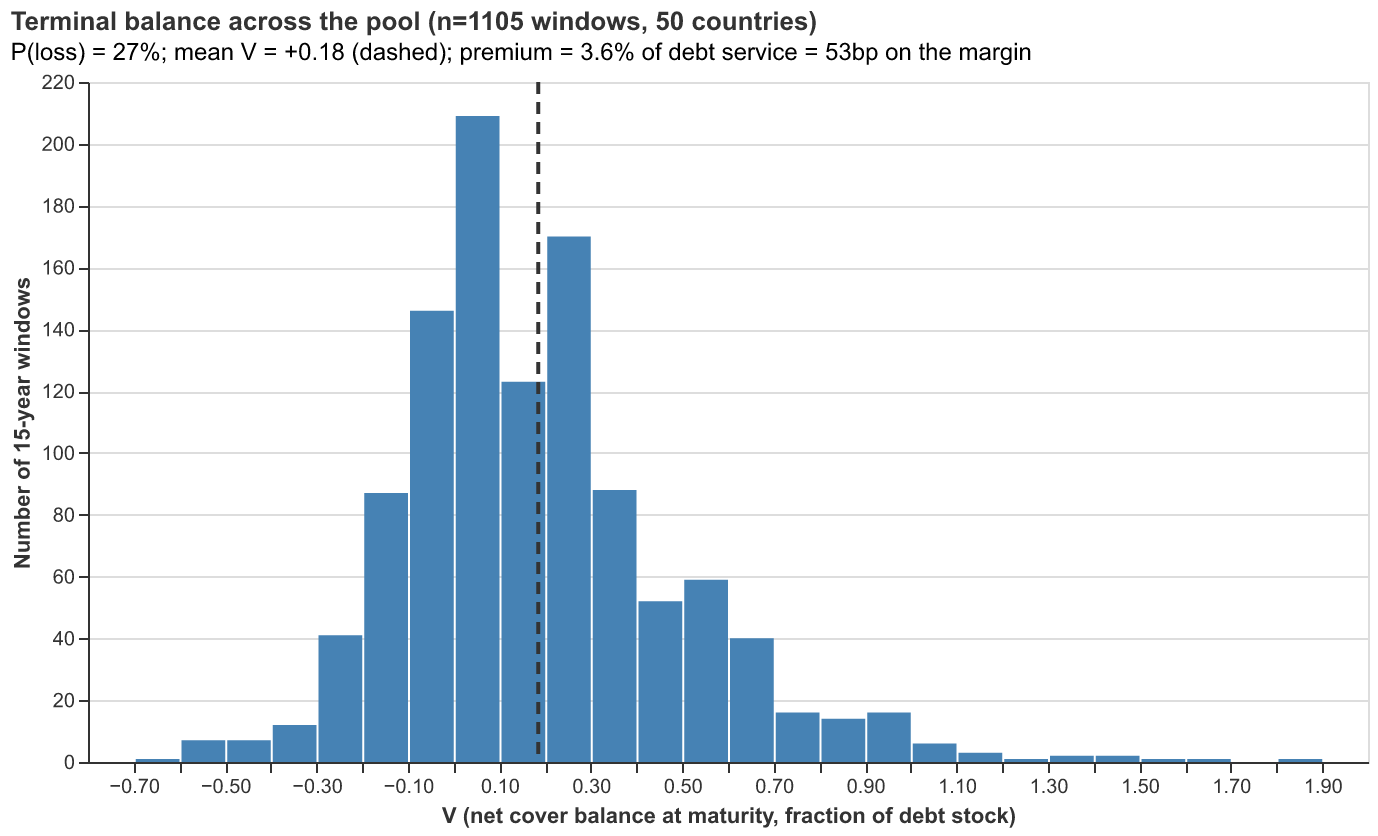

In [7]:
#| label: fig-hist-pooled
#| fig-cap: "Net cover balance at maturity, every rolling 15-year window in the pool (50 countries, closes 1985-2010). Blue: the escrow account ends in surplus and the facility is repaid in full. Red: the facility is short, and the average depth of that red mass is the premium."
mean_rule = alt.Chart(pd.DataFrame({"V": [pool["V"].mean()]})).mark_rule(
    color="#333", strokeDash=[6, 4], strokeWidth=2).encode(x=alt.X("V:Q"))

hist = alt.Chart(pool).mark_bar().encode(
    x=alt.X("V:Q", bin=alt.Bin(maxbins=40),
            title="V  (net cover balance at maturity, fraction of debt stock)"),
    y=alt.Y("count():Q", title=f"Number of {window_length}-year windows"),
    color=alt.condition(alt.datum.V < 0, alt.value("crimson"), alt.value("steelblue")),
    tooltip=[alt.Tooltip("count():Q", title="windows")],
)

(hist + mean_rule).properties(
    width=640, height=340,
    title=alt.TitleParams(
        f"Terminal balance across the pool (n={len(pool)} windows, {pool['iso3'].nunique()} countries)",
        subtitle=[f"P(loss) = {p_loss:.0%};  mean V = {pool['V'].mean():+.2f} (dashed);  "
                  f"premium = {psi_pool:.1%} of debt service = {dr_pool * 1e4:.0f}bp on the margin"],
        anchor="start"),
)

## Country by country

Pooling is a pricing choice, not a fact about the risk. @fig-rate-by-country prices the same cover on each country's own windows (26 of them wherever the WDI series runs unbroken from 1985), quoting the margin-equivalent $\Delta r$ — the number an investor in that country would see.

The dispersion is wide and the distribution is skewed. The median African country prices at **41bp** and 60% of countries sit below 50bp, but Libya (236bp), the Democratic Republic of Congo (157bp), Algeria (125bp), Ethiopia (124bp) and The Gambia (116bp) sit far out in the right tail. At the other end, five countries — Egypt, Guinea, Kenya, Liberia and South Sudan — have no window since 1985 that ends below its close-year level at all, so their actuarially fair premium is exactly zero. Nigeria, the case traced above, prices at 90bp.

The pooled premium of 53bp is not a diversification gain over these country numbers: expected loss is linear, so pooling can only *average*, and the pooled figure exceeds the unweighted country mean of 49bp only because the heavy-tailed countries happen to contribute slightly more windows. What pooling buys sits on the capital side rather than the premium side — the variance of the facility's aggregate outcome falls with the number of imperfectly correlated exposures, and that is what determines the solvency capital standing behind the promise, not its price.

It follows that a single pooled price is a cross-subsidy from the Kenyas to the Libyas, and one that sponsors can see as clearly as the facility can. That is an adverse-selection problem to be designed around — through risk-banded pricing, mandatory participation within a programme, or a deliberate public-policy decision to subsidise the tail — rather than an artefact to be averaged away.

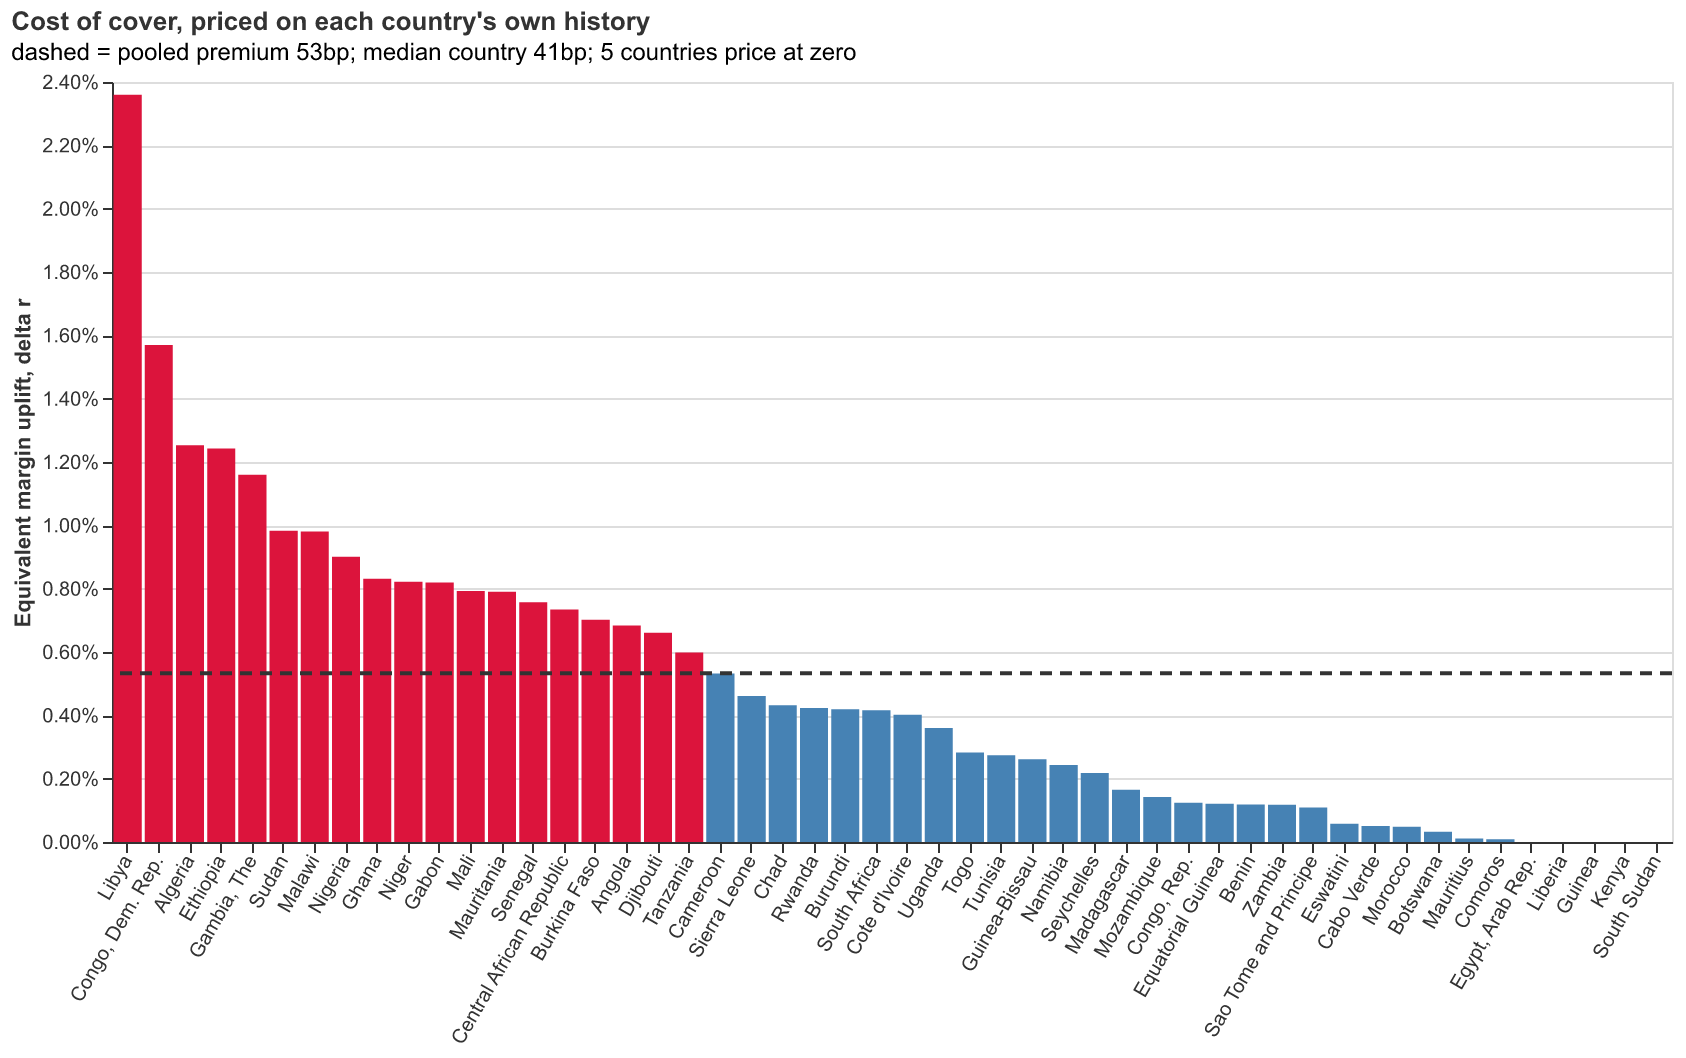

In [8]:
#| label: fig-rate-by-country
#| fig-cap: "Actuarially fair cover priced country by country: the margin-equivalent uplift on a 15-year annuity-amortising loan at 5%. Dashed line: the pooled premium charged to everyone."
order = by_country["country"].tolist()
pooled_rule = alt.Chart(pd.DataFrame({"y": [dr_pool]})).mark_rule(
    color="#333", strokeDash=[6, 4], strokeWidth=2).encode(y=alt.Y("y:Q"))

rate_bar = alt.Chart(by_country).mark_bar().encode(
    x=alt.X("country:N", sort=order, title=None, axis=alt.Axis(labelAngle=-60)),
    y=alt.Y("rate_increase:Q", title="Equivalent margin uplift, delta r",
            axis=alt.Axis(format=".2%")),
    color=alt.condition(alt.datum.rate_increase > dr_pool,
                        alt.value("crimson"), alt.value("steelblue")),
    tooltip=["country", alt.Tooltip("rate_increase:Q", format=".2%"),
             alt.Tooltip("psi:Q", title="premium (share of debt service)", format=".2%"),
             alt.Tooltip("prob_loss:Q", title="P(loss)", format=".0%"),
             alt.Tooltip("mean_V:Q", title="mean V", format="+.3f"),
             "n_windows"],
)

(rate_bar + pooled_rule).properties(
    width=780, height=380,
    title=alt.TitleParams(
        "Cost of cover, priced on each country's own history",
        subtitle=[f"dashed = pooled premium {dr_pool * 1e4:.0f}bp;  "
                  f"median country {by_country['rate_increase'].median() * 1e4:.0f}bp;  "
                  f"{(by_country['psi'] == 0).sum()} countries price at zero"],
        anchor="start"),
)

## Outstanding robustness checks

The numbers above are a single point estimate from one sample, one window length and one definition of indexation. The following checks are outstanding; each is a small extension of the machinery already in this document.

- **Sampling error on $\Psi$.** The 1,105 windows are heavily overlapping (each country contributes 26 windows drawn from 40 annual observations), so a naive standard error is badly understated. *How:* country-block bootstrap — resample the 50 countries with replacement, recompute $\Psi$ and $\Delta r$ on each draw (10,000 draws), report the 5th–95th percentile band. A stationary block bootstrap over close years within country gives the complementary time-dimension band.
- **The cyclicality period of the real exchange rate.** The whole affordability result rests on $Q$ mean-reverting inside a 15-year tenor; the length of that cycle is currently asserted rather than estimated. *How:* fit an AR(1) on $\ln Q$ country by country and as a pooled panel with country fixed effects (bias-correct the pooled estimate), report the implied half-lives and set them against the tenor. Complement with a panel unit-root test (Im–Pesaran–Shin): $\ln Q$ being a random walk is the null under which no facility of this kind is priceable.
- **Delayed inflation adjustment.** The project is assumed to reprice with $P_{i,t}$ contemporaneously. Real PPAs reset annually, off a lagged index, and often with a cap. *How:* replace $Q_{i,t}$ by $P_{i,t-k}/S_{i,t}$ for $k \in \{0.25, 0.5, 1\}$ years, and by a capped variant in which the tariff rises by $\min(\pi_t, \bar{\pi})$, then re-price. The lag bites hardest exactly where the premium is largest — in the high-inflation tail — so this is the sensitivity most likely to move the headline.
- **Sample period.** A 1985 start includes the 1994 CFA devaluation and the Sudanese and Congolese hyperinflations; a 1995 start excludes the first and prices at 29bp rather than 53bp. *How:* re-run the pooled premium for starts in $\{1985, 1990, 1995, 2000\}$ and report $n$, $\Psi$, $P(\text{loss})$ and $\Delta r$ in one table, so the reader sees which episodes the price is carrying instead of having to guess.
- **Window length.** Tenor and cover period are the same parameter here, and a shorter tenor gives mean reversion less time to work. *How:* recompute the premium for $n \in \{10, 12, 15, 20, 25\}$ and plot $\Delta r$ against $n$. The expected shape — premium falling steeply in $n$ — is itself the argument for long-tenor cover and deserves a figure of its own.
- **Country groupings.** The pooled price hides an exchange-rate-regime structure: CFA/EUR-linked, ZAR-linked and independent floats face different mechanics. *How:* re-run the pool within each regime using the `fx_regime` map already defined in the setup cell, reporting per-regime $\Psi$, $P(\text{loss})$ and within-regime dispersion. A commodity-exporter split is the natural second cut.
- **Correlation across countries and groups.** Diversification is the facility's capital argument, and it depends on how much of the risk is common. *How:* build the matrix of pairwise correlations of annual $\Delta \ln Q$, ordered by regime, and report mean within-regime and across-regime correlations. The CFA bloc, moving against a common EUR anchor, is the obvious concentration; a single-factor decomposition (share of variance taken by the first principal component) turns this into the number that sizes the capital.
- **Understanding the intertemporal hedge.** The result rests on two distinct mechanisms that the exhibits above conflate, and separating them is the strongest robustness check available. *How:* (i) *within-window reversion* — decompose each window's $V$ into its drawing phase and its repayment phase, and show what fraction of gross drawings is recovered by maturity in the windows that end positive; (ii) *premium banking across windows* — 73% of windows never pay out at all, so the facility accumulates premium income against the ones that do. Simulate the facility's running balance over a rolling cohort of vintages (say five new projects a year for twenty years) to show how long it takes to fund the first tail loss out of premium, and how sensitive that is to the correlation structure above. Together these say whether the price is doing genuine intertemporal work or is merely the average of a heavy-tailed variable.

# The real exchange rate: measuring the risk the project actually bears {#sec-index}

Data: WDI CPI and official exchange rate series for African countries, 1985–2024, in `data/wdi_africa_long.csv` (Lesotho excluded for uncorrected CPI basket breaks in 1999, 2002 and 2009). We construct $Q = P/S$ per country and plot it against the nominal rate $S$: the gap between the two lines is the inflation component that indexed revenues reprice automatically.
